# 01 — Eyes open vs eyes closed

**Goal:** load real EEG with MNE and see the first effect any EEG setup should show: the **alpha rhythm**.

When you close your eyes, the visual cortex at the back of the head starts oscillating at about 8–12 Hz.
Hans Berger saw it in 1929, in the very first human EEG. If our analysis can't find it, something is wrong with the analysis.

**Data:** [PhysioNet EEG Motor Movement/Imagery](https://physionet.org/content/eegmmidb/1.0.0/) — 109 subjects, 64 electrodes, 160 samples per second.
Each subject starts with two 1-minute baselines:

| Run | Condition |
|-----|-----------|
| 1 | Eyes open, resting |
| 2 | Eyes closed, resting |

**Expected result:** more power between 8 and 12 Hz with eyes closed, mostly over the occipital electrodes (O1, Oz, O2).

In [1]:
import matplotlib.pyplot as plt
import mne
import numpy as np
from mne.datasets import eegbci

mne.set_log_level("WARNING")  # keep the output readable

SUBJECT = 1  # try other subjects: 1 to 109
RUNS = {"eyes open": 1, "eyes closed": 2}
OCCIPITAL = ["O1", "Oz", "O2"]
ALPHA = (8, 12)  # Hz

## 1. Load the recordings

`eegbci.load_data` downloads the files to `~/mne_data` the first time (about 2.5 MB per run), then reuses them.

Two clean-up steps after loading:
- `standardize` renames the channels to standard names (`Fc5.` becomes `FC5`).
- `set_montage` gives each electrode its position on the head, which we need for scalp maps.

In [2]:
raws = {}
for condition, run in RUNS.items():
    [path] = eegbci.load_data(SUBJECT, [run], update_path=True)
    raw = mne.io.read_raw_edf(path, preload=True)
    eegbci.standardize(raw)
    raw.set_montage("colin27_1005")
    raws[condition] = raw

raw = raws["eyes open"]
print(f"{len(raw.ch_names)} channels, {raw.info['sfreq']:.0f} Hz, {raw.times[-1]:.0f} s per run")

64 channels, 160 Hz, 61 s per run


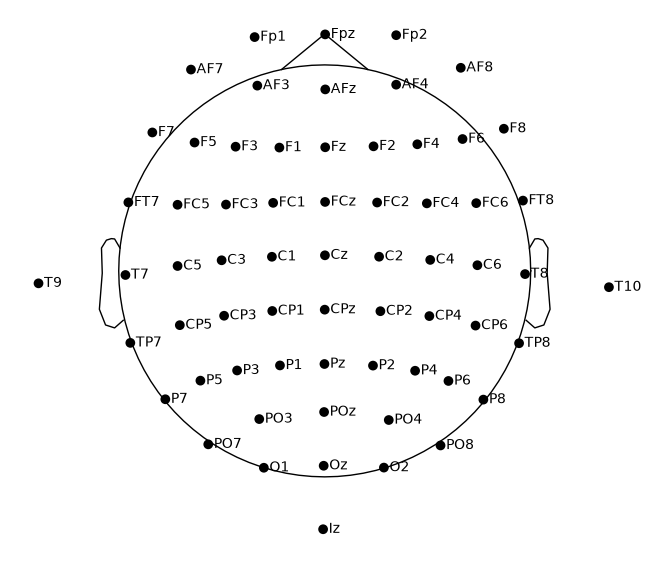

In [3]:
raw.plot_sensors(show_names=True, sphere="eeglab");

## 2. Look at the raw signal

Four seconds of the three occipital channels, side by side.
With eyes closed you should see regular waves at about 10 per second.

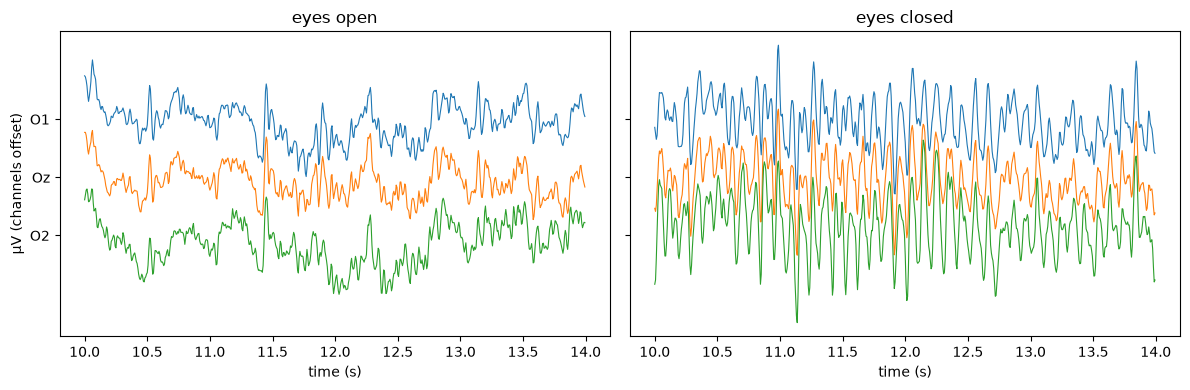

In [4]:
start, duration = 10, 4  # seconds
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (condition, raw) in zip(axes, raws.items()):
    data, times = raw.get_data(picks=OCCIPITAL, tmin=start, tmax=start + duration, return_times=True)
    for i, (name, signal) in enumerate(zip(OCCIPITAL, data * 1e6)):  # volts -> microvolts
        ax.plot(times, signal - 150 * i, lw=0.8, label=name)
    ax.set(title=condition, xlabel="time (s)")
    ax.set_yticks([-150 * i for i in range(len(OCCIPITAL))], OCCIPITAL)
axes[0].set_ylabel("µV (channels offset)")
fig.tight_layout()

## 3. Power spectrum

The spectrum shows how much of the signal sits at each frequency.
`compute_psd` uses Welch's method: it cuts the minute into short windows, takes the spectrum of each and averages them.

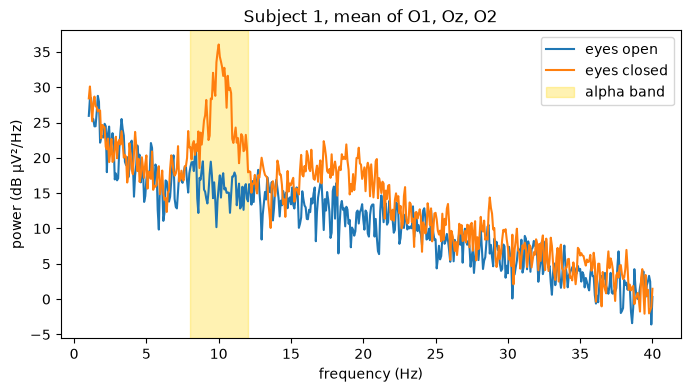

In [5]:
spectra = {}
for condition, raw in raws.items():
    psd = raw.compute_psd(method="welch", fmin=1, fmax=40)
    power, freqs = psd.get_data(return_freqs=True)
    spectra[condition] = power * 1e12  # V²/Hz -> µV²/Hz

occipital_idx = [raw.ch_names.index(ch) for ch in OCCIPITAL]

fig, ax = plt.subplots(figsize=(8, 4))
for condition, power in spectra.items():
    ax.plot(freqs, 10 * np.log10(power[occipital_idx].mean(axis=0)), label=condition)
ax.axvspan(*ALPHA, color="gold", alpha=0.3, label="alpha band")
ax.set(xlabel="frequency (Hz)", ylabel="power (dB µV²/Hz)", title=f"Subject {SUBJECT}, mean of {', '.join(OCCIPITAL)}")
ax.legend();

## 4. Put a number on it

Mean power in the alpha band over the occipital channels, and the frequency of the peak.

In [6]:
in_alpha = (freqs >= ALPHA[0]) & (freqs <= ALPHA[1])
search = (freqs >= 6) & (freqs <= 14)

alpha_power = {}
for condition, power in spectra.items():
    occ = power[occipital_idx].mean(axis=0)
    alpha_power[condition] = occ[in_alpha].mean()
    peak = freqs[search][np.argmax(occ[search])]
    print(f"{condition:12s} alpha power {alpha_power[condition]:7.1f} µV²/Hz, peak at {peak:.1f} Hz")

ratio = alpha_power["eyes closed"] / alpha_power["eyes open"]
print(f"\nEyes closed / eyes open: x{ratio:.1f}")

eyes open    alpha power    45.4 µV²/Hz, peak at 8.4 Hz
eyes closed  alpha power   719.9 µV²/Hz, peak at 10.0 Hz

Eyes closed / eyes open: x15.9


## 5. Where on the head?

Alpha power for every electrode, drawn on the scalp. The same colour scale is used for both conditions.
The third map is the difference: if the effect comes from the visual cortex, it should be strongest at the back.

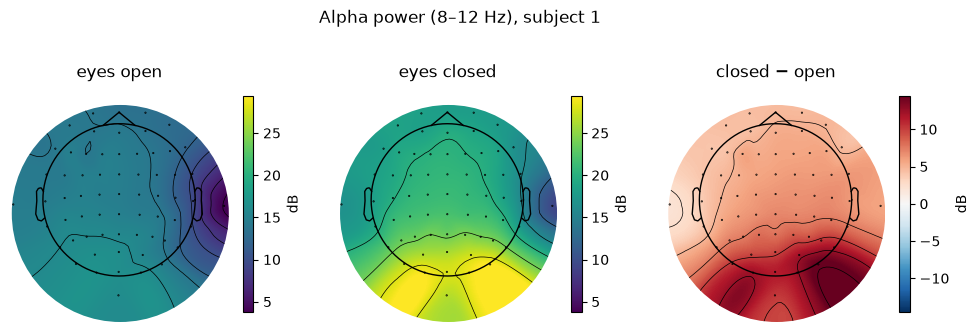

In [7]:
alpha_db = {c: 10 * np.log10(p[:, in_alpha].mean(axis=1)) for c, p in spectra.items()}
vlim = (min(v.min() for v in alpha_db.values()), max(v.max() for v in alpha_db.values()))
maps = {**alpha_db, "closed − open": alpha_db["eyes closed"] - alpha_db["eyes open"]}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, values) in zip(axes, maps.items()):
    is_diff = title == "closed − open"
    im, _ = mne.viz.plot_topomap(
        values, raw.info, axes=ax, show=False, sphere="eeglab",
        cmap="RdBu_r" if is_diff else "viridis",
        vlim=(-max(abs(values)), max(abs(values))) if is_diff else vlim,
    )
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.7, label="dB")
fig.suptitle(f"Alpha power ({ALPHA[0]}–{ALPHA[1]} Hz), subject {SUBJECT}");

## What this shows

- With eyes closed, power between 8 and 12 Hz rises sharply over the back of the head (about 16 times for subject 1): the alpha rhythm.
- Alpha is by far the biggest change. There is a smaller rise around 15–25 Hz, and below 8 Hz the two curves overlap, so the signal isn't just getting louder overall.
- This is a sanity check for everything that follows. The same pipeline (load, spectrum, band power) is how we will look for motor imagery, which shows up as a *drop* in the 8–30 Hz band over the motor cortex.

**Try:** change `SUBJECT` and run everything again. Most people show the effect, but not all of them, and not equally strongly.